# Street Network Classification — Persistence Landscapes

Full pipeline using persistence landscape vectors to classify street network morphology
(gridiron, cul_de_sac, organico, hibrido).

**Feature sets explored**
| Name | Dims | Description |
|---|---|---|
| `flat_raw` | 15 000 | raw flattened landscape (30 levels × 500 pts) |
| `flat_l1norm` | 15 000 | flat vector divided by total area (L1 norm) |
| `flat_maxnorm` | 15 000 | flat vector divided by max value |
| `sum_per_level` | 30 | area under each landscape level |
| `sum_per_level_norm` | 30 | same, divided by total area |
| `mean_per_level` | 30 | mean value of each landscape level |
| `stats_per_level` | 120 | mean, std, max, skewness per level |
| `first_k_levels` | 5 000 | only first 10 levels (less sparse) |

**Classifiers**: Random Forest, SVM (RBF), Logistic Regression  
**Evaluation**: 5-fold stratified CV + leave-one-city-out CV

In [1]:
import numpy as np
import re
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from scipy.stats import skew
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.manifold import TSNE
import matplotlib.patches as mpatches

## 1. Load data

In [3]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
DATA_DIR = LEVELSET_ROOT / "processed_data" / "test_us_cities" / "manually_filtered_01"
LABEL_RE = re.compile(r'(gridiron|cul_de_sac)')
CITY_RE  = re.compile(r'^(.+?)_(gridiron|cul_de_sac)')

flat_vecs, land_vals, xgrids, labels, cities = [], [], [], [], []

for folder in sorted(DATA_DIR.iterdir()):
    npz_path = folder / 'persistence_landscape_h1.npz'
    if not npz_path.exists():
        continue
    lm = LABEL_RE.search(folder.name)
    cm = CITY_RE.match(folder.name)
    if not lm or not cm:
        continue
    d = np.load(npz_path)
    flat_vecs.append(d['flat_vector'])       # (15000,)
    land_vals.append(d['landscape_values'])  # (30, 500)
    xgrids.append(d['x_grid'])               # (500,)
    labels.append(lm.group(1))
    cities.append(cm.group(1))

X_flat = np.array(flat_vecs)   # (n, 15000)
X_land = np.array(land_vals)   # (n, 30, 500)
y_raw  = np.array(labels)
c      = np.array(cities)

le = LabelEncoder()
y  = le.fit_transform(y_raw)
n  = len(y)

CLASS_COLORS = {'gridiron': '#4C72B0', 'cul_de_sac': '#DD8452',
                'organico': '#55A868',  'hibrido':    '#C44E52'}

print(f'Samples: {n}  |  Features per sample: {X_flat.shape[1]}')
print('Classes:', dict(zip(*np.unique(y_raw, return_counts=True))))
print('Cities:', dict(Counter(cities)))

Samples: 90  |  Features per sample: 25000
Classes: {'cul_de_sac': 39, 'gridiron': 51}
Cities: {'cary_town': 15, 'chandler': 3, 'charleston': 4, 'fort_collins': 8, 'peachtree': 5, 'philadelphia': 38, 'salt_lake': 14, 'santafe': 3}


## 2. Build feature sets

> **Note on x_grids**: each sample's landscape is evaluated on its own grid (range 0 to its own max-death value),
> so the 500 columns are NOT on a common scale across samples. The `flat_raw` vector therefore mixes
> scale and shape information. The normalized variants remove the scale component.

In [4]:
# grid_maxes: max filtration value per sample (= x_grid[-1]).
# Dividing by grid_maxes aligns the x-axis: col k -> k/499 for every sample.
grid_maxes = np.array([g[-1] for g in xgrids]).reshape(-1, 1)

# --- Normalizations of the flat vector ---
total_area = X_flat.sum(axis=1, keepdims=True)
total_area = np.where(total_area == 0, 1, total_area)
X_flat_l1   = X_flat / total_area                          # L1 norm

max_val = X_flat.max(axis=1, keepdims=True)
max_val = np.where(max_val == 0, 1, max_val)
X_flat_max  = X_flat / max_val                             # max norm
X_flat_grid = X_flat / grid_maxes                          # x-axis aligned norm

# --- Aggregations over the 500-point grid (per landscape level) ---
X_sum   = X_land.sum(axis=2)                               # (n, 30) — area per level
X_sum_n = X_sum / X_sum.sum(axis=1, keepdims=True).clip(1) # normalized areas
X_mean  = X_land.mean(axis=2)                              # (n, 30)

# --- Per-level statistics: mean, std, max, skewness → (n, 120) ---
X_stats = np.hstack([
    X_land.mean(axis=2),
    X_land.std(axis=2),
    X_land.max(axis=2),
    np.nan_to_num(np.array([[skew(X_land[i, k, :]) for k in range(50)] for i in range(n)]), nan=0.0),
])

# --- First 10 landscape levels only (less sparse) ---
X_first10 = X_land[:, :10, :].reshape(n, -1)              # (n, 5000)
X_first10_n = X_first10 / X_first10.sum(axis=1, keepdims=True).clip(1)

feature_sets = {
    'flat_raw':           X_flat,
    'flat_l1norm':        X_flat_l1,
    'flat_maxnorm':       X_flat_max,
    'flat_gridnorm':      X_flat_grid,
    'sum_per_level':      X_sum,
    'sum_per_level_norm': X_sum_n,
    'mean_per_level':     X_mean,
    'stats_per_level':    X_stats,
    'first10_levels':     X_first10,
    'first10_levels_norm':X_first10_n,
}

for name, X in feature_sets.items():
    print(f'  {name:25s}: shape={X.shape}  zeros={( X==0).mean():.2f}')

  flat_raw                 : shape=(90, 25000)  zeros=0.70
  flat_l1norm              : shape=(90, 25000)  zeros=0.70
  flat_maxnorm             : shape=(90, 25000)  zeros=0.70
  flat_gridnorm            : shape=(90, 25000)  zeros=0.70
  sum_per_level            : shape=(90, 50)  zeros=0.22
  sum_per_level_norm       : shape=(90, 50)  zeros=0.22
  mean_per_level           : shape=(90, 50)  zeros=0.22
  stats_per_level          : shape=(90, 200)  zeros=0.22
  first10_levels           : shape=(90, 5000)  zeros=0.40
  first10_levels_norm      : shape=(90, 5000)  zeros=0.40


## 3. Classifiers

In [5]:
def make_classifiers():
    return {
        'RandomForest':  RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
        'SVM_RBF':       Pipeline([('sc', StandardScaler()), ('svm', SVC(kernel='rbf', C=10, gamma='scale'))]),
        'LogReg':        Pipeline([('sc', StandardScaler()), ('lr',  LogisticRegression(max_iter=1000, C=1))]),
    }

## 4. 5-fold stratified CV — all feature sets × all classifiers

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

print(f'{"Feature set":25s} | {"Classifier":14s} | Accuracy')
print('-' * 60)
for feat_name, X in feature_sets.items():
    results[feat_name] = {}
    for clf_name, clf in make_classifiers().items():
        scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy')
        results[feat_name][clf_name] = scores
        print(f'{feat_name:25s} | {clf_name:14s} | {scores.mean():.3f} ± {scores.std():.3f}')
    print()

Feature set               | Classifier     | Accuracy
------------------------------------------------------------
flat_raw                  | RandomForest   | 0.811 ± 0.103
flat_raw                  | SVM_RBF        | 0.800 ± 0.075
flat_raw                  | LogReg         | 0.822 ± 0.074

flat_l1norm               | RandomForest   | 0.833 ± 0.086
flat_l1norm               | SVM_RBF        | 0.856 ± 0.083
flat_l1norm               | LogReg         | 0.833 ± 0.050

flat_maxnorm              | RandomForest   | 0.811 ± 0.075
flat_maxnorm              | SVM_RBF        | 0.833 ± 0.079
flat_maxnorm              | LogReg         | 0.822 ± 0.082

flat_gridnorm             | RandomForest   | 0.811 ± 0.109
flat_gridnorm             | SVM_RBF        | 0.811 ± 0.044
flat_gridnorm             | LogReg         | 0.800 ± 0.090

sum_per_level             | RandomForest   | 0.833 ± 0.035
sum_per_level             | SVM_RBF        | 0.800 ± 0.057
sum_per_level             | LogReg         | 0.822 ± 0.

## 5. Leave-one-city-out CV — all feature sets (RandomForest)

In [7]:
def loco_cv(X, y, cities, clf):
    accs = {}
    for city in np.unique(cities):
        train, test = cities != city, cities == city
        clf.fit(X[train], y[train])
        accs[city] = accuracy_score(y[test], clf.predict(X[test]))
    return accs

print(f'{"city":20s}', end='')
feat_names_short = list(feature_sets.keys())
for fn in feat_names_short:
    print(f'  {fn[:12]:>12s}', end='')
print()
print('-' * (20 + 14 * len(feat_names_short)))

loco_results = {}
for feat_name, X in feature_sets.items():
    clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    loco_results[feat_name] = loco_cv(X, y, c, clf)

for city in sorted(np.unique(c)):
    print(f'{city:20s}', end='')
    for fn in feat_names_short:
        print(f'  {loco_results[fn][city]:>12.3f}', end='')
    print()

print('-' * (20 + 14 * len(feat_names_short)))
print(f'{"MEAN":20s}', end='')
for fn in feat_names_short:
    print(f'  {np.mean(list(loco_results[fn].values())):>12.3f}', end='')
print()

city                      flat_raw   flat_l1norm  flat_maxnorm  flat_gridnor  sum_per_leve  sum_per_leve  mean_per_lev  stats_per_le  first10_leve  first10_leve
----------------------------------------------------------------------------------------------------------------------------------------------------------------
cary_town                    0.867         0.800         0.733         0.867         0.933         0.800         0.933         0.933         0.533         0.667
chandler                     0.000         0.667         0.667         0.333         0.333         0.667         0.333         0.333         0.000         0.000
charleston                   0.750         1.000         1.000         0.750         1.000         1.000         1.000         1.000         0.750         0.750
fort_collins                 0.500         0.875         0.875         0.625         0.750         0.750         0.750         0.750         0.625         1.000
peachtree                    1.000

## 6. Summary bar chart — 5-fold CV

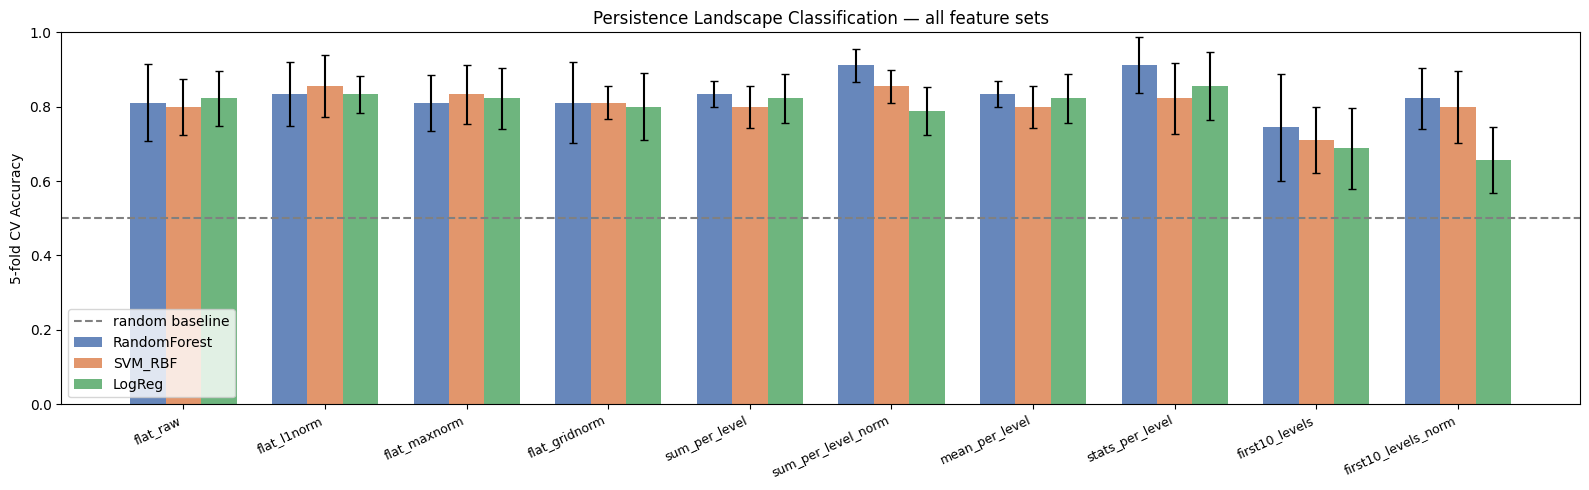

In [8]:
clf_names = list(make_classifiers().keys())
feat_names = list(feature_sets.keys())
x = np.arange(len(feat_names))
width = 0.25
clf_colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(16, 5))
for i, (clf_name, col) in enumerate(zip(clf_names, clf_colors)):
    means = [results[f][clf_name].mean() for f in feat_names]
    stds  = [results[f][clf_name].std()  for f in feat_names]
    ax.bar(x + i*width, means, width, yerr=stds, label=clf_name,
           color=col, capsize=3, alpha=0.85)

ax.axhline(1/len(le.classes_), color='gray', linestyle='--', label='random baseline')
ax.set_xticks(x + width)
ax.set_xticklabels(feat_names, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('5-fold CV Accuracy')
ax.set_ylim(0, 1)
ax.set_title('Persistence Landscape Classification — all feature sets')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Confusion matrix — best feature set + best classifier

Best: sum_per_level_norm + RandomForest  →  0.911
              precision    recall  f1-score   support

  cul_de_sac       0.90      0.90      0.90        39
    gridiron       0.92      0.92      0.92        51

    accuracy                           0.91        90
   macro avg       0.91      0.91      0.91        90
weighted avg       0.91      0.91      0.91        90



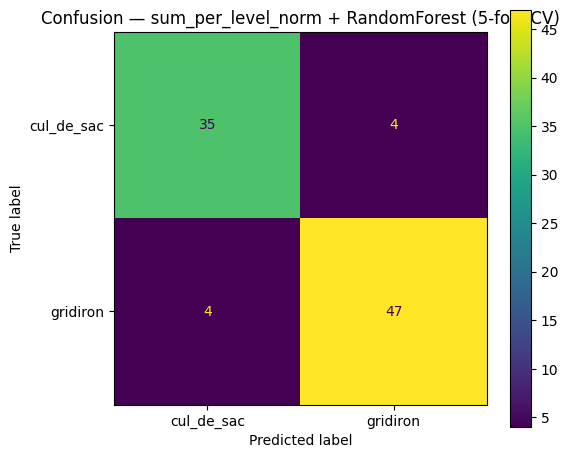

In [9]:
# Find best combo
best_score, best_feat, best_clf_name = 0, None, None
for fn in feat_names:
    for cn in clf_names:
        m = results[fn][cn].mean()
        if m > best_score:
            best_score, best_feat, best_clf_name = m, fn, cn

print(f'Best: {best_feat} + {best_clf_name}  →  {best_score:.3f}')

best_clf = make_classifiers()[best_clf_name]
y_pred = cross_val_predict(best_clf, feature_sets[best_feat], y, cv=cv)

print(classification_report(y, y_pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=le.classes_, ax=ax)
ax.set_title(f'Confusion — {best_feat} + {best_clf_name} (5-fold CV)')
plt.tight_layout()
plt.show()

## 8. PCA visualization — raw vs normalized flat vector

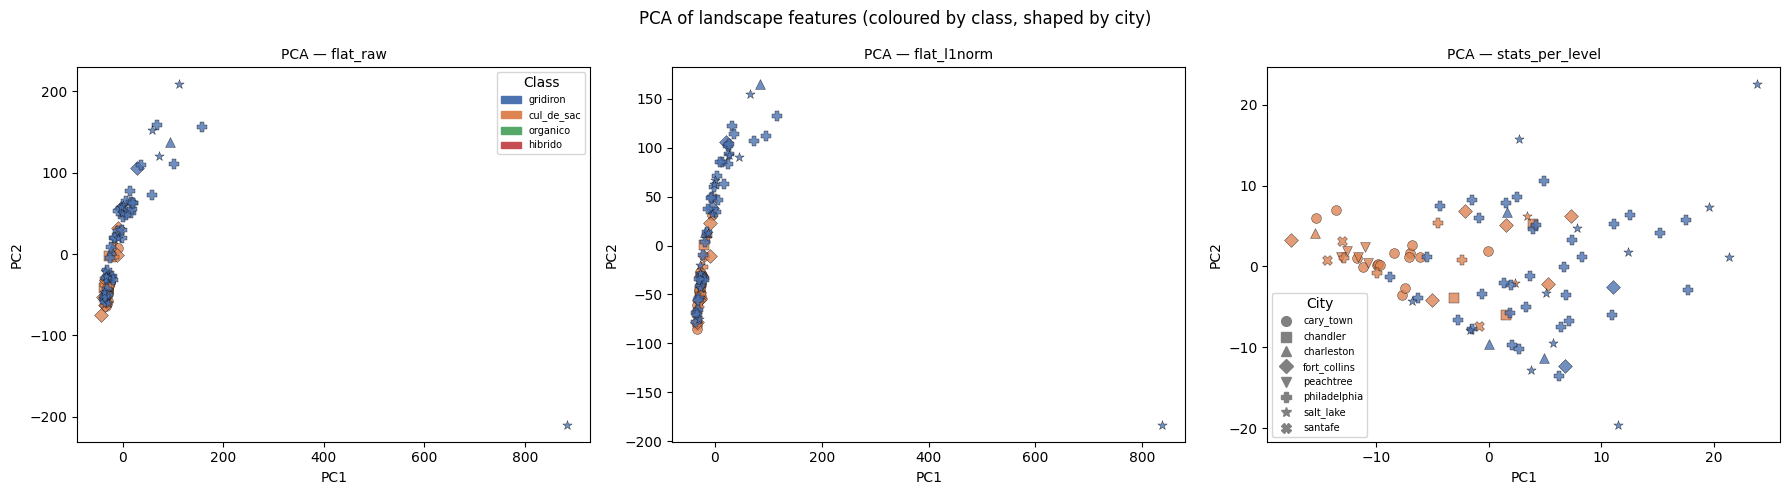

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
CITY_MARKERS = {city: m for city, m in zip(sorted(set(cities)),
                ['o','s','^','D','v','P','*','X','h'])}

for ax, (feat_name, X) in zip(axes, [
    ('flat_raw',    X_flat),
    ('flat_l1norm', X_flat_l1),
    ('stats_per_level', X_stats),
]):
    Xp = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
    for cls in np.unique(y_raw):
        for city in np.unique(c):
            mask = (y_raw == cls) & (c == city)
            if mask.sum() == 0: continue
            ax.scatter(Xp[mask, 0], Xp[mask, 1],
                       color=CLASS_COLORS[cls], marker=CITY_MARKERS[city],
                       s=50, alpha=0.8, linewidths=0.3, edgecolors='k')
    ax.set_title(f'PCA — {feat_name}', fontsize=10)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

class_patches = [mpatches.Patch(color=v, label=k) for k, v in CLASS_COLORS.items()]
city_handles  = [plt.Line2D([0],[0], marker=v, color='gray', linestyle='',
                             markersize=7, label=k) for k, v in CITY_MARKERS.items()]
axes[0].legend(handles=class_patches, title='Class', fontsize=7)
axes[2].legend(handles=city_handles,  title='City',  fontsize=7)
plt.suptitle('PCA of landscape features (coloured by class, shaped by city)', fontsize=12)
plt.tight_layout()
plt.show()